# Comparative Analysis of K-Means, DBSCAN and HDBSCAN

## Project Objective

This project compares three clustering algorithms:

1. K-Means
2. DBSCAN
3. HDBSCAN

The objective is to investigate how the algorithms perform under different data characteristics, including:

- Cluster shape
- Noise and outliers
- Varying cluster densities
- Increasing dimensionality

The algorithms will be evaluated using both synthetic and real-world datasets.

### Datasets

1. Synthetic benchmark dataset
2. Wholesale Customers dataset
3. Dry Bean dataset

In [3]:
# Numerical operations
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt

# Dataset generation
from sklearn.datasets import make_blobs, make_moons, make_circles

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Clustering algorithms
from sklearn.cluster import KMeans, DBSCAN

# Dimensionality reduction
from sklearn.decomposition import PCA

# Evaluation metrics
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


## Experimental Methodology

The experiments are designed to investigate how different data characteristics affect the performance of K-Means, DBSCAN and HDBSCAN.

Four main factors will be investigated:

### 1. Cluster Shape
The algorithms will be tested on datasets containing different geometric cluster structures.

### 2. Noise and Outliers
Increasing levels of noise will be introduced to evaluate the robustness of each algorithm.

### 3. Cluster Density
Datasets with clusters of different densities will be generated to investigate how density variation affects clustering performance.

### 4. Dimensionality
The number of features will be progressively increased to investigate the effect of dimensionality on clustering performance.

Where possible, only one experimental factor will be changed at a time while the remaining factors are kept consistent.

# 2. Synthetic Benchmark Experiments

Synthetic datasets allow individual data characteristics to be controlled while keeping other factors relatively consistent.

This makes it possible to investigate the conditions under which different clustering algorithms succeed or fail.

## 2.1 Experiment 1 — Effect of Cluster Shape

The first experiment investigates the effect of cluster geometry.

Three different cluster structures are considered:

1. Gaussian blobs — compact and approximately spherical clusters
2. Two moons — non-convex curved clusters
3. Concentric circles — nested non-convex clusters

These datasets provide known ground-truth labels, allowing the clustering results to later be evaluated using external clustering metrics such as Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI).

In [4]:
# Number of observations in each synthetic dataset
n_samples = 600

# Dataset 1: Gaussian blobs
X_blobs, y_blobs = make_blobs(
    n_samples=n_samples,
    centers=3,
    cluster_std=0.70,
    random_state=RANDOM_STATE
)

# Dataset 2: Two moons
X_moons, y_moons = make_moons(
    n_samples=n_samples,
    noise=0.06,
    random_state=RANDOM_STATE
)

# Dataset 3: Concentric circles
X_circles, y_circles = make_circles(
    n_samples=n_samples,
    factor=0.45,
    noise=0.04,
    random_state=RANDOM_STATE
)

print("Blobs shape:", X_blobs.shape)
print("Moons shape:", X_moons.shape)
print("Circles shape:", X_circles.shape)

Blobs shape: (600, 2)
Moons shape: (600, 2)
Circles shape: (600, 2)


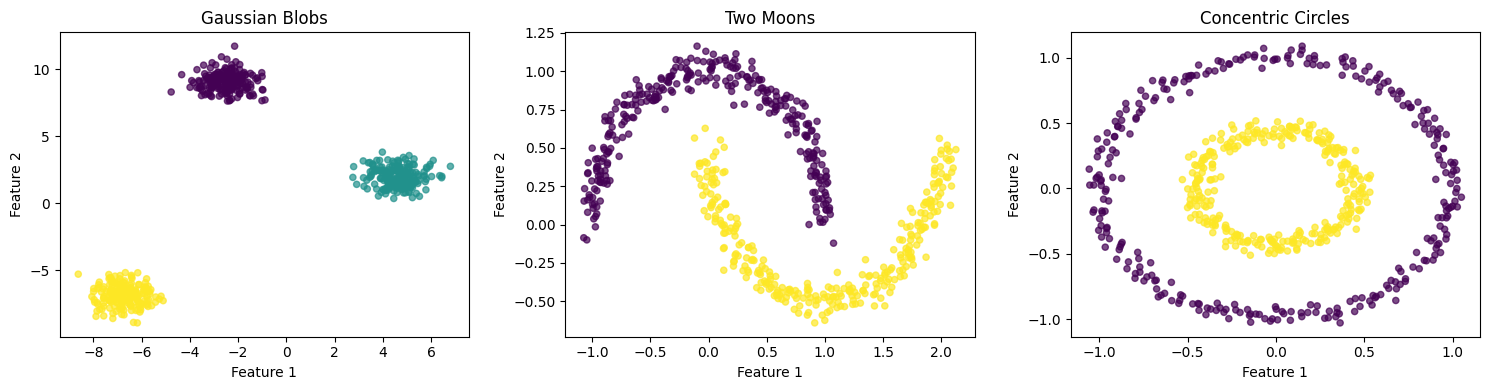

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Gaussian blobs
axes[0].scatter(
    X_blobs[:, 0],
    X_blobs[:, 1],
    c=y_blobs,
    s=20,
    alpha=0.7
)
axes[0].set_title("Gaussian Blobs")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

# Two moons
axes[1].scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    s=20,
    alpha=0.7
)
axes[1].set_title("Two Moons")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

# Concentric circles
axes[2].scatter(
    X_circles[:, 0],
    X_circles[:, 1],
    c=y_circles,
    s=20,
    alpha=0.7
)
axes[2].set_title("Concentric Circles")
axes[2].set_xlabel("Feature 1")
axes[2].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

### Hypotheses

Before applying the clustering algorithms, the following hypotheses are proposed:

**H1 — Gaussian Blobs**

K-Means is expected to perform well because the clusters are compact and approximately spherical. DBSCAN and HDBSCAN are also expected to identify the separated dense regions successfully.

**H2 — Two Moons**

K-Means is expected to perform worse because the clusters are non-convex and cannot be naturally represented using cluster centroids. Density-based methods are expected to better preserve the curved cluster structures.

**H3 — Concentric Circles**

K-Means is expected to struggle to separate the inner and outer circular structures because centroid-based partitioning does not naturally represent nested clusters. Density-based approaches are expected to perform better when suitable parameter settings are used.

### 2.1.1 K-Means Clustering

K-Means partitions observations into a predefined number of clusters by assigning each observation to its nearest cluster centroid and iteratively updating the centroids.

In this experiment, K-Means is applied to the three synthetic datasets:

- Gaussian Blobs: 3 clusters
- Two Moons: 2 clusters
- Concentric Circles: 2 clusters

The number of clusters is provided to K-Means based on the known structure of each synthetic dataset.

This experiment investigates whether K-Means can recover the ground-truth clusters when the geometric shape of the clusters changes.

In [7]:
# K-Means for Gaussian blobs
kmeans_blobs = KMeans(
    n_clusters=3,
    random_state=RANDOM_STATE,
    n_init=10
)

y_kmeans_blobs = kmeans_blobs.fit_predict(X_blobs)


# K-Means for Two Moons
kmeans_moons = KMeans(
    n_clusters=2,
    random_state=RANDOM_STATE,
    n_init=10
)

y_kmeans_moons = kmeans_moons.fit_predict(X_moons)


# K-Means for Concentric Circles
kmeans_circles = KMeans(
    n_clusters=2,
    random_state=RANDOM_STATE,
    n_init=10
)

y_kmeans_circles = kmeans_circles.fit_predict(X_circles)


print("K-Means clustering completed.")

K-Means clustering completed.


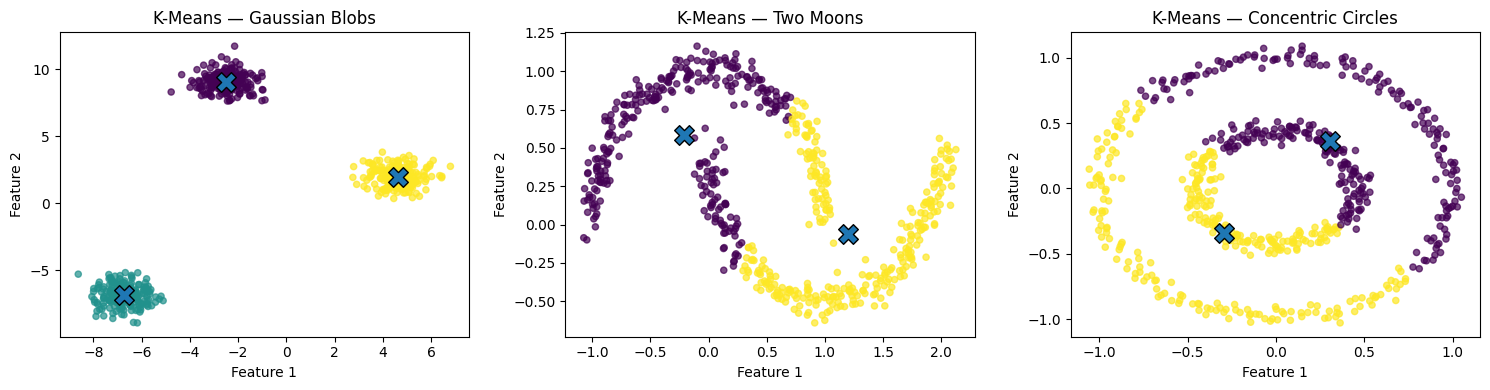

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Gaussian blobs
axes[0].scatter(
    X_blobs[:, 0],
    X_blobs[:, 1],
    c=y_kmeans_blobs,
    s=20,
    alpha=0.7
)

axes[0].scatter(
    kmeans_blobs.cluster_centers_[:, 0],
    kmeans_blobs.cluster_centers_[:, 1],
    marker="X",
    s=200,
    edgecolor="black"
)

axes[0].set_title("K-Means — Gaussian Blobs")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")


# Two moons
axes[1].scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_kmeans_moons,
    s=20,
    alpha=0.7
)

axes[1].scatter(
    kmeans_moons.cluster_centers_[:, 0],
    kmeans_moons.cluster_centers_[:, 1],
    marker="X",
    s=200,
    edgecolor="black"
)

axes[1].set_title("K-Means — Two Moons")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")


# Concentric circles
axes[2].scatter(
    X_circles[:, 0],
    X_circles[:, 1],
    c=y_kmeans_circles,
    s=20,
    alpha=0.7
)

axes[2].scatter(
    kmeans_circles.cluster_centers_[:, 0],
    kmeans_circles.cluster_centers_[:, 1],
    marker="X",
    s=200,
    edgecolor="black"
)

axes[2].set_title("K-Means — Concentric Circles")
axes[2].set_xlabel("Feature 1")
axes[2].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

In [9]:
# Adjusted Rand Index
ari_blobs = adjusted_rand_score(y_blobs, y_kmeans_blobs)
ari_moons = adjusted_rand_score(y_moons, y_kmeans_moons)
ari_circles = adjusted_rand_score(y_circles, y_kmeans_circles)

# Normalized Mutual Information
nmi_blobs = normalized_mutual_info_score(y_blobs, y_kmeans_blobs)
nmi_moons = normalized_mutual_info_score(y_moons, y_kmeans_moons)
nmi_circles = normalized_mutual_info_score(y_circles, y_kmeans_circles)

# Silhouette Score
sil_blobs = silhouette_score(X_blobs, y_kmeans_blobs)
sil_moons = silhouette_score(X_moons, y_kmeans_moons)
sil_circles = silhouette_score(X_circles, y_kmeans_circles)

print("K-Means Results")
print("-" * 55)

print(f"{'Dataset':<20} {'ARI':>10} {'NMI':>10} {'Silhouette':>12}")
print("-" * 55)

print(
    f"{'Gaussian Blobs':<20}"
    f"{ari_blobs:>10.3f}"
    f"{nmi_blobs:>10.3f}"
    f"{sil_blobs:>12.3f}"
)

print(
    f"{'Two Moons':<20}"
    f"{ari_moons:>10.3f}"
    f"{nmi_moons:>10.3f}"
    f"{sil_moons:>12.3f}"
)

print(
    f"{'Concentric Circles':<20}"
    f"{ari_circles:>10.3f}"
    f"{nmi_circles:>10.3f}"
    f"{sil_circles:>12.3f}"
)

K-Means Results
-------------------------------------------------------
Dataset                     ARI        NMI   Silhouette
-------------------------------------------------------
Gaussian Blobs           1.000     1.000       0.890
Two Moons                0.242     0.184       0.490
Concentric Circles      -0.002     0.000       0.343


In [10]:
kmeans_results = pd.DataFrame({
    "Algorithm": ["K-Means", "K-Means", "K-Means"],
    "Dataset": [
        "Gaussian Blobs",
        "Two Moons",
        "Concentric Circles"
    ],
    "ARI": [
        ari_blobs,
        ari_moons,
        ari_circles
    ],
    "NMI": [
        nmi_blobs,
        nmi_moons,
        nmi_circles
    ],
    "Silhouette": [
        sil_blobs,
        sil_moons,
        sil_circles
    ]
})

kmeans_results.round(3)

,Algorithm,Dataset,ARI,NMI,Silhouette
0,K-Means,Gaussian Blobs,1.000,1.000,0.890
1,K-Means,Two Moons,0.242,0.184,0.490
2,K-Means,Concentric Circles,-0.002,0.000,0.343
